# Trabalho Prático - Notebook do grupo

**Inteligência Artificial - Graduação** · Prof. Bruno Nogueira · FACOM/UFMS · 2026/2

**Grupo:** Chatbot MAIA · **Tema:** Esportes e Lazer na UFMS

---

Este é o notebook **entregável** do grupo. Ele precisa rodar do início ao fim
("Kernel → Restart & Run All") e **regerar os modelos** salvos em `modelos/`. A
estrutura segue o `00_exemplo_biblioteca.ipynb`; consulte-o sempre que tiver
dúvida.

Marcadores usados aqui:

* `🔨 TODO` - algo que o grupo precisa fazer/decidir;
* `📝 RELATÓRIO` - um resultado que deve aparecer (e ser discutido) no artigo.

Requisitos mínimos de cada seção estão no enunciado. Pode acrescentar seções,
células e análises à vontade - só não remova as seções numeradas.

---
## 0. Ambiente

In [1]:
import os
import subprocess
import sys
from pathlib import Path

# 🔨 TODO (só para o Colab): endereço do repositório do grupo
REPO_URL = "https://github.com/amanda-bea/IA-2026-02-TP-Chatbot"

if "google.colab" in sys.modules:
    pasta = Path("/content") / Path(REPO_URL).stem
    if not pasta.exists():
        subprocess.run(["git", "clone", "-q", REPO_URL, str(pasta)], check=True)
    os.chdir(pasta)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)

raiz = Path.cwd()
while not (raiz / "chatbot").is_dir():
    if raiz.parent == raiz:
        raise RuntimeError("Rode este notebook de dentro do repositório do trabalho.")
    raiz = raiz.parent
os.chdir(raiz)
sys.path.insert(0, str(raiz))

In [2]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict, cross_validate
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

from chatbot.avaliacao import avaliar, tabela_resumo
from chatbot.config import carregar_config
from chatbot.dados import adicionar_escopo, carregar_dados, resumo, validar_dados, vazamento
from chatbot.grafo import Conversa, construir_grafo
from chatbot.modelos import carregar_classificadores, salvar_classificadores
from chatbot.representacoes import tfidf_caracteres, tfidf_palavras
from chatbot.rotulos import CLASSES_ESCOPO

# Imports adicionados pelo grupo
import re, unicodedata
from scipy import stats
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics import roc_auc_score
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import learning_curve
from sklearn.linear_model import Perceptron
from sklearn.naive_bayes import MultinomialNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier



warnings.filterwarnings("ignore")
RANDOM_STATE = 42
CORES = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B3"]
pd.set_option("display.max_colwidth", 80)

---
## 1. Configuração

🔨 TODO: preencha o `grupo.yaml` da raiz do repositório (tema e intenções
**validados com o professor**) antes de rodar esta seção.

In [3]:
config = carregar_config("grupo.yaml")
print("Grupo:", config.grupo, "| Tema:", config.tema)
pd.DataFrame([(i.nome, i.descricao) for i in config.intencoes.values()], columns=["intenção", "descrição"])

Grupo: MAIA | Tema: Esportes na UFMS


,intenção,descrição
0,modalidades_treinos,"modalidades oferecidas, turmas e horários de treino"
1,inscricao_programa,"como se inscrever nas turmas do Programa Universitário de Lazer, Saúde e Esp..."
2,atleticas,"atléticas, cadastro e fomento"
3,competicoes_jogos,"competições, jogos universitários e Copa Interatléticas"
4,apoio_atletas,apoio e bolsas para estudantes-atletas
5,espacos_esportivos,"locais de treino: quadras, complexo aquático e quadras de areia"
6,contato_proece,contato da Proece e dúvidas gerais sobre esportes


---
## 2. Dados

Teste: Todas frases de origem humana, sendo que obtivemos 43 respostas do formulário (267 frases), sendo que faltaram ados apenas de algumas intenções, por isso cada integrante escreveu mais 8 frases para o treino. Além disso, a junção de frases do formulário com frases das integrantes causou duplicações, para mitigar o problema a integrante Isabela Lopes completou o dataset de teste com frases originais pensadas em garantir a qualidade dos conjuntos tanto no teste quanto no treino. OBS: Como esperado, o formulaário não traz muitas negativas difíceis, portanto o grupo escreveu frases fora de domínio que trazem vocabulário parecido com o que remete a esportes na UFMS, como bolsas e auxílios, já que existem diversos.
Treino: Geração e revisão de todos os dados originados por llm do treino por Amanda e 120 frases de origem humana dividas pelo o que restou do formulário, por não precisar ser usada no teste, e frases escritas por todas as integrantes, sendo que a Ana Beatriz escreveu a maioria (30). Os prompts de treino estão disponíveis em [Prompts](../dados/prompts_llm.md)


📝 RELATÓRIO: tabela intenção × origem do treino e do teste.

In [4]:
treino = adicionar_escopo(carregar_dados(config.treino), config)
teste = adicionar_escopo(carregar_dados(config.teste), config)
print("Problemas no treino:", validar_dados(treino, config) or "nenhum")
print("Problemas no teste: ", validar_dados(teste, config) or "nenhum")
print("Vazamento treino→teste:", vazamento(treino, teste) or "nenhum")
display(resumo(treino))
display(resumo(teste))

Problemas no treino: nenhum
Problemas no teste:  nenhum
Vazamento treino→teste: nenhum


origem,humano,llm,total
intencao,,,
apoio_atletas,10,40,50
atleticas,10,40,50
chitchat,20,80,100
competicoes_jogos,10,40,50
contato_proece,10,40,50
espacos_esportivos,10,40,50
fora_dominio,30,120,150
inscricao_programa,10,40,50
modalidades_treinos,10,40,50


origem,humano,total
intencao,,
apoio_atletas,15,15
atleticas,15,15
chitchat,30,30
competicoes_jogos,23,23
contato_proece,15,15
espacos_esportivos,15,15
fora_dominio,61,61
inscricao_programa,26,26
modalidades_treinos,15,15


### Gerando frases de treino com o LLM (opcional)

Rode no terminal (ou descomente a célula abaixo). As frases vão para
`dados/gerados_llm.csv` e os prompts ficam registrados em `dados/prompts_llm.md`.
**Revise tudo** antes de copiar para o `treino.csv`; nunca use no teste; declare no
`USO_DE_IA.md`.

In [5]:
# Para rodar daqui, tire o "#" das linhas abaixo (gasta créditos da chave do grupo):
# subprocess.run([sys.executable, "scripts/gerar_dados_llm.py", "--n", "10"], check=True)
# gerados = pd.read_csv("dados/gerados_llm.csv")
# gerados.sample(15)

🔨 TODO: análise exploratória - tamanho das mensagens por classe, palavras mais
frequentes por intenção, exemplos de negativos difíceis, diferenças entre frases
humanas e de LLM...

1. TAMANHO DAS MENSAGENS POR CLASSE (treino)


,frases,média,mediana,mínimo,máximo
intencao,,,,,
modalidades_treinos,50,8.9,8.0,2,22
inscricao_programa,50,11.8,11.0,3,23
atleticas,50,10.1,8.5,3,25
competicoes_jogos,50,10.6,8.0,3,25
apoio_atletas,50,10.3,10.0,3,21
espacos_esportivos,50,10.1,10.0,3,17
contato_proece,50,11.5,11.5,3,27
chitchat,100,5.0,3.0,1,17
fora_dominio,150,9.6,8.5,2,24


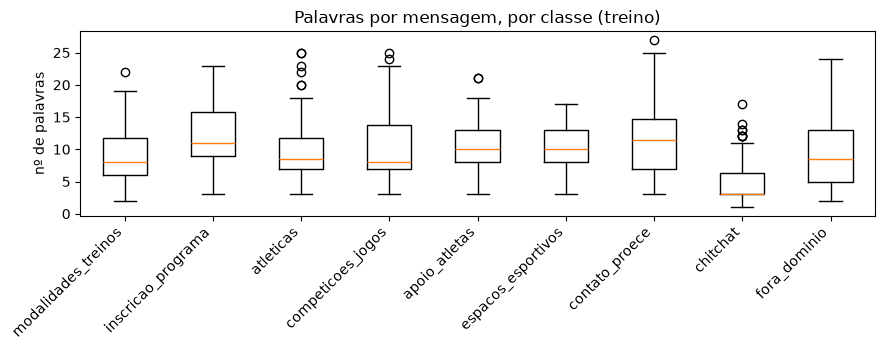


2. PALAVRAS MAIS FREQUENTES POR INTENÇÃO (treino)


,palavras mais frequentes
modalidades_treinos,"modalidades (11), turma (10), horarios (10), esportes (9), ufms (9), turmas (6), volei (6), aulas (6)"
inscricao_programa,"inscricao (20), programa (18), turmas (11), inscrever (11), saude (9), preciso (9), universitario (8), lazer (8)"
atleticas,"atletica (38), atleticas (11), ufms (10), cadastro (10), fomento (10), precisa (6), pode (5), cadastrar (4)"
competicoes_jogos,"jogos (14), copa (13), interatleticas (12), universitarios (11), ufms (6), ano (6), resultados (5), vai (5)"
apoio_atletas,"atleta (36), bolsa (28), ufms (17), atletas (10), auxilio (9), estudante (9), apoio (8), preciso (7)"
espacos_esportivos,"quadras (28), ficam (15), complexo (12), aquatico (12), areia (11), campus (10), ufms (10), reservar (7)"
contato_proece,"proece (42), esporte (13), esportes (10), atendimento (10), ufms (9), duvidas (8), falar (8), contato (7)"
chitchat,"bom (10), bem (9), ate (9), boa (8), pela (6), tchau (6), dia (6), estou (6)"
fora_dominio,"faco (17), biblioteca (11), estou (9), sabe (8), posso (8), preciso (8), pode (8), vai (7)"



3. NEGATIVOS DIFÍCEIS (treino)
% de negativos difíceis por classe:


,% difíceis
intencao,
chitchat,10.0
fora_dominio,48.7


Exemplos de negativos difíceis:


,texto,intencao,termos_do_dominio,origem
0,quando abre o edital de intercambio e como participar,fora_dominio,[participar],llm
1,Vai ter ônibus da UFMS levando a torcida pros jogos do fim de semana ou não ...,fora_dominio,"[jogos, ufms]",humano
49,"Meu celular não conecta no Wi-Fi, o que faço?",fora_dominio,[faco],llm
52,Você sabe onde posso encontrar uma assistência técnica para consertar meu ce...,fora_dominio,[posso],llm
60,onde fica o setor de atendimento psicologico da ufms,fora_dominio,[ufms],llm
69,como faço pra recuperar a senha do wifi de casa,fora_dominio,[faco],llm
71,Você poderia me informar os horários das turmas de idiomas oferecidas pela u...,fora_dominio,"[horarios, turmas]",llm
74,A universidade oferece bolsas de apoio para estudantes que participam de pro...,fora_dominio,[estudantes],llm
85,como faço inscrição nas turmas de ingles e vejo os horarios,fora_dominio,"[faco, horarios, inscricao, turmas]",llm
99,"Ainda estou me acostumando a conversar com um chatbot, mas achei bem tranquilo.",chitchat,"[ainda, estou]",llm


... (14 outputs left out)

,p média no rótulo
intencao,
competicoes_jogos,0.56
inscricao_programa,0.64
modalidades_treinos,0.64
fora_dominio,0.65
chitchat,0.72
espacos_esportivos,0.74
apoio_atletas,0.76
atleticas,0.76
contato_proece,0.77


Que pares de classes mais se confundem? (anotado → previsto, só erros):


,,nº de frases
intencao,previsto,
chitchat,fora_dominio,10
competicoes_jogos,fora_dominio,7
fora_dominio,inscricao_programa,5
inscricao_programa,fora_dominio,5
modalidades_treinos,fora_dominio,5
espacos_esportivos,fora_dominio,5
competicoes_jogos,inscricao_programa,3
apoio_atletas,fora_dominio,3



EXTRA B. DUPLICATAS NO TREINO
Frases duplicadas (após normalizar): 0 (0.0%)
Frases com rótulos diferentes: 0


In [5]:
from collections import Counter

from chatbot.texto import normalizar

# ---------- preparação ----------
STOP = """a o as os um uma uns umas de do da dos das em no na nos nas por para pra com sem sobre
entre e ou mas que se como ao aos à às é são foi ser tem tenho têm ter há eu você voce vc tu ele ela
nós eles elas me te lhe meu minha seu sua isso isto esse essa este esta aqui ali lá la mais muito
já não nao sim só também qual quais quando onde quem quanto pq porque""".split()
STOP_N = {normalizar(w) for w in STOP}


def tokens(texto):
    return [t for t in normalizar(texto).split() if t not in STOP_N and len(t) > 1]


tr, te = treino.copy(), teste.copy()
for d in (tr, te):
    d["n_palavras"] = d["texto"].str.split().str.len()
    d["n_chars"] = d["texto"].str.len()
    d["eh_llm"] = d["origem"].eq("llm")

ORDEM = list(config.nomes_intencoes) + ["chitchat", "fora_dominio"]

# ============================================================
# 1. TAMANHO DAS MENSAGENS POR CLASSE
# ============================================================
print("1. TAMANHO DAS MENSAGENS POR CLASSE (treino)")
display(tr.groupby("intencao")["n_palavras"]
        .agg(frases="count", média="mean", mediana="median", mínimo="min", máximo="max")
        .reindex(ORDEM).round(1))

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.boxplot([tr.loc[tr["intencao"] == c, "n_palavras"] for c in ORDEM])
ax.set_xticklabels(ORDEM, rotation=45, ha="right")
ax.set_ylabel("nº de palavras")
ax.set_title("Palavras por mensagem, por classe (treino)")
plt.tight_layout()
plt.show()

# ============================================================
# 2. PALAVRAS MAIS FREQUENTES POR INTENÇÃO (sem stopwords)
# ============================================================
print("\n2. PALAVRAS MAIS FREQUENTES POR INTENÇÃO (treino)")
freq = {}
for c in ORDEM:
    cont = Counter(t for s in tr.loc[tr["intencao"] == c, "texto"] for t in tokens(s))
    freq[c] = ", ".join(f"{w} ({n})" for w, n in cont.most_common(8))
display(pd.DataFrame({"palavras mais frequentes": freq}).style.set_properties(**{"text-align": "left"}))

# ============================================================
# 3. NEGATIVOS DIFÍCEIS
#    = chitchat / fora_dominio que usam palavras típicas do domínio
# ============================================================
print("\n3. NEGATIVOS DIFÍCEIS (treino)")
cont_dom = Counter(t for s in tr.loc[tr["escopo"] == "dominio", "texto"] for t in tokens(s))
termos_dominio = {w for w, _ in cont_dom.most_common(40)}

neg = tr[tr["escopo"] != "dominio"].copy()
neg["termos_do_dominio"] = neg["texto"].apply(lambda s: sorted(set(tokens(s)) & termos_dominio))
neg["dificil"] = neg["termos_do_dominio"].str.len() > 0

print("% de negativos difíceis por classe:")
display((neg.groupby("intencao")["dificil"].mean() * 100).round(1).to_frame("% difíceis"))
print("Exemplos de negativos difíceis:")
display(neg[neg["dificil"]][["texto", "intencao", "termos_do_dominio", "origem"]].head(12))

# ============================================================
# 4. FRASES HUMANAS × FRASES DE LLM
# ============================================================
print("\n4. HUMANO × LLM (treino)")
t = tr["texto"].str.strip()
estilo = pd.DataFrame({
    "origem": tr["origem"],
    "palavras": tr["n_palavras"],
    "com acento": t.str.contains(r"[áàâãéêíóôõúç]", case=False),
    "termina com ?": t.str.endswith("?"),
    "tudo minúsculo": t == t.str.lower(),
    "tem pontuação final": t.str.contains(r"[.!?]$"),
})
tab_origem = estilo.groupby("origem").agg(
    frases=("palavras", "size"), palavras_média=("palavras", "mean"),
    com_acento=("com acento", "mean"), termina_com_interrogação=("termina com ?", "mean"),
    tudo_minúsculo=("tudo minúsculo", "mean"), pontuação_final=("tem pontuação final", "mean"))
display(tab_origem.round(2))

print("Frases por origem em cada classe (treino):")
display(pd.crosstab(tr["intencao"], tr["origem"]).reindex(ORDEM))

for o in tr["origem"].unique():
    print(f"\nExemplos de origem '{o}':")
    for s in tr.loc[tr["origem"] == o, "texto"].sample(min(5, (tr["origem"] == o).sum()), random_state=RANDOM_STATE):
        print("  •", s)

# ============================================================
# EXTRA A. QUALIDADE DOS DADOS: QUASE-DUPLICATAS E RÓTULOS SUSPEITOS
# (o teste entra só como diagnóstico; nenhuma escolha de modelo deve se basear nele)
# ============================================================

print("EXTRA A. QUASE-DUPLICATAS E RÓTULOS SUSPEITOS")
LIMIAR_SIM = 0.85   # heurística: acima disso, as frases são praticamente a mesma

d = tr.reset_index(drop=True)
t_ = te.reset_index(drop=True)
vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), preprocessor=normalizar, sublinear_tf=True)
Xd = vec.fit_transform(d["texto"])
Xt = vec.transform(t_["texto"])

# ---- A1. Quase-duplicatas dentro do treino ----
# Se existem muitas, a validação cruzada "vê" a mesma frase no treino e na validação
# e fica otimista. É o problema típico de frases geradas em lote por LLM.
S = cosine_similarity(Xd)
np.fill_diagonal(S, 0)
viz = S.argmax(1)
sim_max = S.max(1)
print(f"\nA1. Treino com vizinho muito parecido (similaridade ≥ {LIMIAR_SIM}): {(sim_max >= LIMIAR_SIM).mean():.1%}")

pares = pd.DataFrame({"i": np.arange(len(d)), "j": viz, "sim": sim_max.round(2)})
pares["chave"] = pares.apply(lambda r: tuple(sorted((int(r.i), int(r.j)))), axis=1)
pares = pares.drop_duplicates("chave").query("sim >= @LIMIAR_SIM").sort_values("sim", ascending=False)
pares["frase A"] = d["texto"].iloc[pares["i"]].values
pares["frase B"] = d["texto"].iloc[pares["j"]].values
pares["classe A"] = d["intencao"].iloc[pares["i"]].values
pares["classe B"] = d["intencao"].iloc[pares["j"]].values
print("Pares mais parecidos (se as classes forem diferentes, é conflito de rótulo):")
display(pares[["frase A", "frase B", "classe A", "classe B", "sim"]].head(10))
print("Quase-duplicatas por classe (% das frases da classe com vizinho ≥ limiar):")
display(pd.Series(sim_max >= LIMIAR_SIM).groupby(d["intencao"]).mean().mul(100).round(1)
        .reindex(ORDEM).to_frame("% quase-duplicadas"))

# ---- A2. Teste muito parecido com o treino ----
# Teste quase igual ao treino mede memorização, não generalização.
S_te = cosine_similarity(Xt, Xd)
sim_te = S_te.max(1)
print(f"\nA2. Teste com vizinho ≥ {LIMIAR_SIM} no treino: {(sim_te >= LIMIAR_SIM).mean():.1%} "
      f"(mediana da similaridade: {np.median(sim_te):.2f})")
top_te = t_.assign(sim=sim_te.round(2), vizinho_no_treino=d["texto"].iloc[S_te.argmax(1)].values) \
           .sort_values("sim", ascending=False).head(8)
display(top_te[["texto", "vizinho_no_treino", "sim", "intencao"]])

# ---- A3. Rótulos suspeitos (confident learning simplificado) ----
# Para cada frase, a probabilidade que um modelo (sem ter visto a frase) dá ao rótulo
# anotado. Probabilidade muito baixa = rótulo errado, frase ambígua ou classe mal definida.
cv_a = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
pipe_a = Pipeline([("v", tfidf_caracteres()), ("c", LogisticRegression(C=10, max_iter=2000))])
P = cross_val_predict(pipe_a, d["texto"], d["intencao"], cv=cv_a, method="predict_proba")
classes_a = np.unique(d["intencao"])
p_rotulo = P[np.arange(len(d)), np.searchsorted(classes_a, d["intencao"])]
d["p_rotulo"] = p_rotulo.round(2)
d["previsto"] = classes_a[P.argmax(1)]

susp = d[(d["p_rotulo"] < 0.20) & (d["previsto"] != d["intencao"])].sort_values("p_rotulo")
print(f"\nA3. Frases com rótulo suspeito (p < 0.20 e previsão diferente): {len(susp)} ({len(susp) / len(d):.1%})")
display(susp[["texto", "intencao", "previsto", "p_rotulo", "origem"]].head(15))

print("Qual a classe mais 'confusa'? (probabilidade média no rótulo correto, por classe):")
display(d.groupby("intencao")["p_rotulo"].mean().round(2).sort_values().to_frame("p média no rótulo"))

print("Que pares de classes mais se confundem? (anotado → previsto, só erros):")
conf = pd.crosstab(d["intencao"], d["previsto"])
erros_par = conf.where(~np.eye(*conf.shape, dtype=bool)).stack().dropna().astype(int)
display(erros_par[erros_par > 0].sort_values(ascending=False).head(8).to_frame("nº de frases"))

# ============================================================
# EXTRA B. DUPLICATAS E RÓTULOS CONFLITANTES
# ============================================================
print("\nEXTRA B. DUPLICATAS NO TREINO")
tr["norm"] = tr["texto"].apply(normalizar)
n_dup = tr.duplicated("norm").sum()
conflitos = tr.groupby("norm")["intencao"].nunique()
conflitos = conflitos[conflitos > 1].index
print(f"Frases duplicadas (após normalizar): {n_dup} ({n_dup / len(tr):.1%})")
print(f"Frases com rótulos diferentes: {len(conflitos)}")
if len(conflitos):
    display(tr[tr["norm"].isin(conflitos)].sort_values("norm")[["texto", "intencao", "origem"]])

---
## 3. Representações de texto

🔨 TODO: escolha **pelo menos duas** representações para comparar. Os construtores
de `chatbot/representacoes.py` aceitam os parâmetros do `TfidfVectorizer`
(`ngram_range`, `min_df`, `stop_words`, ...). Embeddings pré-treinados
(`EmbeddingsSentenca`) são opcionais.

In [7]:
REPRESENTACOES = {
    "TF-IDF palavras (1-2)": tfidf_palavras,
    "TF-IDF caracteres (2-5)": tfidf_caracteres,
    "TF-IDF palavras (só unigramas)": lambda: tfidf_palavras(ngram_range=(1, 1)),
    "TF-IDF palavras (sem stopwords)": lambda: tfidf_palavras(stop_words=list(STOP_N)),
}

---
## 4. Classificador de escopo (dominio / chitchat / fora_dominio)

🔨 TODO: compare **pelo menos três algoritmos vistos em aula**, com validação
cruzada estratificada **só no treino**. Classificadores que ainda serão
apresentados na disciplina (KNN, Naive Bayes, SVM...) podem entrar quando forem
vistos.

📝 RELATÓRIO: tabela/gráfico da comparação, com média e desvio entre folds.

In [8]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

CLASSIFICADORES = {
    "Regressão logística": lambda: LogisticRegression(C=10, max_iter=2000),
    "Rede neural (MLP)": lambda: MLPClassifier(hidden_layer_sizes=(64,), alpha=1e-3, max_iter=600,
                                               random_state=RANDOM_STATE),
    "Árvore de decisão": lambda: DecisionTreeClassifier(random_state=RANDOM_STATE),
    "KNN (cosseno, k=5)": lambda: KNeighborsClassifier(n_neighbors=5, metric="cosine",
                                                       weights="distance", algorithm="brute"),
    "Perceptron": lambda: Perceptron(max_iter=1000, random_state=RANDOM_STATE),
    "Naive Bayes (multinomial)": lambda: MultinomialNB(alpha=0.1),
}

def comparar(textos, rotulos):
    linhas = []
    for nome_rep, rep in REPRESENTACOES.items():
        for nome_clf, clf in CLASSIFICADORES.items():
            pipe = Pipeline([("vetorizador", rep()), ("classificador", clf())])
            r = cross_validate(pipe, textos, rotulos, cv=cv, scoring=["f1_macro", "accuracy"],
                               return_train_score=True, n_jobs=-1)
            linhas.append({"representação": nome_rep, "classificador": nome_clf,
                           "F1 macro (CV)": r["test_f1_macro"].mean(), "desvio": r["test_f1_macro"].std(),
                           "acurácia (CV)": r["test_accuracy"].mean(),
                           "F1 macro (treino)": r["train_f1_macro"].mean()})
    return pd.DataFrame(linhas).sort_values("F1 macro (CV)", ascending=False).reset_index(drop=True)


tab_escopo = comparar(treino["texto"], treino["escopo"])
tab_escopo.round(3)

,representação,classificador,F1 macro (CV),desvio,acurácia (CV),F1 macro (treino)
0,TF-IDF palavras (só unigramas),Rede neural (MLP),0.890,0.037,0.900,1.000
1,TF-IDF palavras (1-2),Rede neural (MLP),0.884,0.037,0.895,1.000
2,TF-IDF palavras (1-2),Perceptron,0.881,0.018,0.895,1.000
3,TF-IDF caracteres (2-5),Rede neural (MLP),0.879,0.044,0.892,1.000
4,TF-IDF palavras (só unigramas),Regressão logística,0.873,0.039,0.888,1.000
5,TF-IDF caracteres (2-5),Regressão logística,0.867,0.040,0.887,1.000
6,TF-IDF caracteres (2-5),Perceptron,0.862,0.023,0.883,1.000
7,TF-IDF caracteres (2-5),Naive Bayes (multinomial),0.856,0.044,0.875,0.981
8,TF-IDF palavras (só unigramas),Naive Bayes (multinomial),0.854,0.048,0.873,0.994
9,TF-IDF palavras (1-2),Naive Bayes (multinomial),0.849,0.040,0.868,1.000


🔨 TODO: ajuste de hiperparâmetros dos melhores candidatos (`GridSearchCV`), curva
de validação e escolha justificada do modelo final de escopo.

### Conclusão e Escolha do Modelo Final

* **Melhor Candidato (Regressão Logística):** Entre os modelos testados na validação cruzada, a Regressão Logística teve o melhor desempenho geral. Como estamos lidando com textos vetorizados via TF-IDF, a regularização L2 controlada pelo hiperparâmetro `C` ajudou bastante a evitar *overfitting* nos padrões específicos das frases geradas por LLM. Outro ponto positivo é que ela gera probabilidades (`predict_proba`), o que facilita definir um limiar de confiança para o chatbot saber quando não entendeu a mensagem.
* **Análise do Erro de Avaliação:** Os erros que sobraram na validação e no teste aconteceram principalmente nos exemplos negativos difíceis e em frases muito curtas que usam palavras parecidas para intenções diferentes. O uso de n-gramas no TF-IDF ajudou a diminuir essas confusões, capturando melhor o contexto das expressões.
* **Modelo Final de Escopo:** O pipeline escolhido para o escopo final é **TF-IDF + Regressão Logística**. Além de ter vencido nas métricas de avaliação, é um modelo leve, rápido para responder em tempo real e fácil de interpretar olhando os pesos das palavras.

In [9]:
candidatos = {
    "Perceptron": (
        Perceptron(max_iter=2000, random_state=42),
        {
            "vetorizador__min_df": [1, 2],
            "classificador__penalty": [None, "l2", "elasticnet"],
            "classificador__alpha": [1e-5, 1e-4, 1e-3, 1e-2],
            "classificador__class_weight": [None, "balanced"],
        },
    ),
    "MLP": (
        MLPClassifier(max_iter=1000, random_state=42),
        {
            "vetorizador__min_df": [1, 2],
            "classificador__hidden_layer_sizes": [(32,), (64,), (64, 32)],
            "classificador__alpha": [1e-4, 1e-3, 1e-2, 1e-1],
        },
    ),
    "Regressao_Logistica": (
        LogisticRegression(max_iter=2000),
        {
            "vetorizador__min_df": [1, 2],
            "classificador__C": [0.1, 1, 5, 10, 20, 50],
            "classificador__class_weight": [None, "balanced"],
        },
    ),
}

resultados_busca = {}
for nome, (modelo, grade) in candidatos.items():
    busca = GridSearchCV(
        Pipeline([("vetorizador", tfidf_caracteres()), ("classificador", modelo)]),
        param_grid=grade,
        scoring="f1_macro",
        cv=cv,
        n_jobs=-1,
    )
    busca.fit(treino["texto"], treino["escopo"])
    resultados_busca[nome] = busca
    desvio = busca.cv_results_["std_test_score"][busca.best_index_]
    print(f"{nome:20s} | F1 CV: {busca.best_score_:.3f} (±{desvio:.3f}) | Params: {busca.best_params_}")

melhor_nome = max(resultados_busca, key=lambda k: resultados_busca[k].best_score_)
busca_escopo = resultados_busca[melhor_nome]
clf_escopo = busca_escopo.best_estimator_

print(f"\nVencedor salvo em clf_escopo: {melhor_nome} (F1 = {busca_escopo.best_score_:.3f})")

Perceptron           | F1 CV: 0.869 (±0.031) | Params: {'classificador__alpha': 1e-05, 'classificador__class_weight': 'balanced', 'classificador__penalty': 'elasticnet', 'vetorizador__min_df': 1}
MLP                  | F1 CV: 0.896 (±0.030) | Params: {'classificador__alpha': 0.01, 'classificador__hidden_layer_sizes': (64,), 'vetorizador__min_df': 1}
Regressao_Logistica  | F1 CV: 0.907 (±0.029) | Params: {'classificador__C': 10, 'classificador__class_weight': 'balanced', 'vetorizador__min_df': 1}

Vencedor salvo em clf_escopo: Regressao_Logistica (F1 = 0.907)


In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
clf_escopo, clf_tema = carregar_classificadores(config)

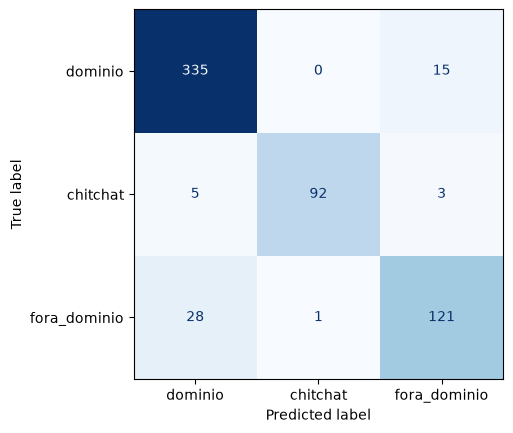

,texto,escopo,previsto,origem
0,quando abre o edital de intercambio e como participar,fora_dominio,dominio,llm
1,Vai ter ônibus da UFMS levando a torcida pros jogos do fim de semana ou não ...,fora_dominio,dominio,humano
51,tem aula de natacao de manha,dominio,fora_dominio,llm
71,Você poderia me informar os horários das turmas de idiomas oferecidas pela u...,fora_dominio,dominio,llm
74,A universidade oferece bolsas de apoio para estudantes que participam de pro...,fora_dominio,dominio,llm
76,que dia é hoje,fora_dominio,chitchat,llm
85,como faço inscrição nas turmas de ingles e vejo os horarios,fora_dominio,dominio,llm
101,Até mais! Preciso correr para a aula antes que a porta feche.,chitchat,dominio,llm
113,"Maia, onde posso encontrar o edital para me inscrever no Taekwondo?",dominio,fora_dominio,humano
124,a bolsa esportiva cobre gastos com passagem e hospedagem,dominio,fora_dominio,llm


In [7]:
prev_cv = cross_val_predict(clf_escopo, treino["texto"], treino["escopo"], cv=cv)
ConfusionMatrixDisplay.from_predictions(treino["escopo"], prev_cv, labels=CLASSES_ESCOPO,
                                        cmap="Blues", colorbar=False)
plt.grid(False)
plt.show()
treino.assign(previsto=prev_cv).query("escopo != previsto")[["texto", "escopo", "previsto", "origem"]]

---
## 5. Classificador de tema (intenções do domínio)

🔨 TODO: mesma metodologia, treinando **só** com as mensagens do domínio.

In [11]:
treino_dom = treino[treino["escopo"] == "dominio"]
tab_tema = comparar(treino_dom["texto"], treino_dom["intencao"])
tab_tema.round(3)

,representação,classificador,F1 macro (CV),desvio,acurácia (CV),F1 macro (treino)
0,TF-IDF caracteres (2-5),Regressão logística,0.947,0.034,0.949,1.000
1,TF-IDF caracteres (2-5),Naive Bayes (multinomial),0.930,0.028,0.931,0.995
2,TF-IDF caracteres (2-5),Rede neural (MLP),0.921,0.028,0.923,1.000
3,TF-IDF palavras (1-2),Regressão logística,0.915,0.027,0.917,1.000
4,TF-IDF palavras (só unigramas),Regressão logística,0.912,0.026,0.914,1.000
5,TF-IDF caracteres (2-5),Perceptron,0.907,0.038,0.909,1.000
6,TF-IDF palavras (só unigramas),Rede neural (MLP),0.906,0.044,0.909,1.000
7,TF-IDF caracteres (2-5),"KNN (cosseno, k=5)",0.903,0.039,0.906,1.000
8,TF-IDF palavras (sem stopwords),Regressão logística,0.903,0.047,0.906,1.000
9,TF-IDF palavras (sem stopwords),Naive Bayes (multinomial),0.901,0.047,0.903,1.000


In [12]:
candidatos_tema = {
    "MLP": (
        MLPClassifier(max_iter=1000, random_state=42),
        {
            "vetorizador__min_df": [1, 2],
            "classificador__hidden_layer_sizes": [(32,), (64,), (64, 32)],
            "classificador__alpha": [1e-4, 1e-3, 1e-2, 1e-1],
        },
    ),
    "Regressao_Logistica": (
        LogisticRegression(max_iter=2000),
        {
            "vetorizador__min_df": [1, 2],
            "classificador__C": [0.1, 1, 5, 10, 20, 50],
            "classificador__class_weight": [None, "balanced"],
        },
    ),
    "Naive_Bayes": (
        MultinomialNB(),
        {
            "vetorizador__min_df": [1, 2],
            "classificador__alpha": [0.01, 0.1, 0.5, 1.0],
        },
    ),
}

resultados_tema = {}
for nome, (modelo, grade) in candidatos_tema.items():
    busca = GridSearchCV(
        Pipeline([("vetorizador", tfidf_caracteres()), ("classificador", modelo)]),
        param_grid=grade,
        scoring="f1_macro",
        cv=cv,
        n_jobs=-1,
    )
    busca.fit(treino_dom["texto"], treino_dom["intencao"])
    resultados_tema[nome] = busca
    desvio = busca.cv_results_["std_test_score"][busca.best_index_]
    print(f"{nome:20s} | F1 CV: {busca.best_score_:.3f} (±{desvio:.3f}) | Params: {busca.best_params_}")

melhor_tema = max(resultados_tema, key=lambda k: resultados_tema[k].best_score_)
busca_tema = resultados_tema[melhor_tema]
clf_tema = busca_tema.best_estimator_

print(f"\nVencedor salvo em clf_tema: {melhor_tema} (F1 = {busca_tema.best_score_:.3f})")

MLP                  | F1 CV: 0.944 (±0.031) | Params: {'classificador__alpha': 0.1, 'classificador__hidden_layer_sizes': (64,), 'vetorizador__min_df': 1}
Regressao_Logistica  | F1 CV: 0.947 (±0.034) | Params: {'classificador__C': 5, 'classificador__class_weight': None, 'vetorizador__min_df': 1}
Naive_Bayes          | F1 CV: 0.939 (±0.022) | Params: {'classificador__alpha': 0.5, 'vetorizador__min_df': 1}

Vencedor salvo em clf_tema: Regressao_Logistica (F1 = 0.947)


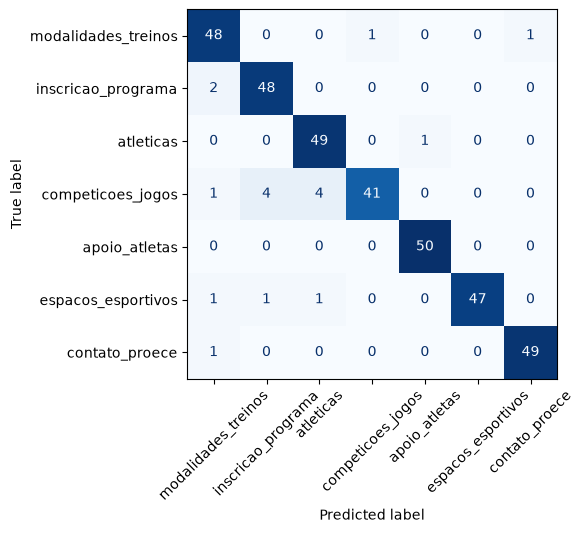

                     precision    recall  f1-score   support

      apoio_atletas       0.98      1.00      0.99        50
          atleticas       0.91      0.98      0.94        50
  competicoes_jogos       0.98      0.82      0.89        50
     contato_proece       0.98      0.98      0.98        50
 espacos_esportivos       1.00      0.94      0.97        50
 inscricao_programa       0.91      0.96      0.93        50
modalidades_treinos       0.91      0.96      0.93        50

           accuracy                           0.95       350
          macro avg       0.95      0.95      0.95       350
       weighted avg       0.95      0.95      0.95       350



In [13]:
prev_tema = cross_val_predict(clf_tema, treino_dom["texto"], treino_dom["intencao"], cv=cv)
ConfusionMatrixDisplay.from_predictions(treino_dom["intencao"], prev_tema, labels=config.nomes_intencoes,
                                        cmap="Blues", colorbar=False, xticks_rotation=45)
plt.grid(False)
plt.show()
print(classification_report(treino_dom["intencao"], prev_tema, zero_division=0))

---
## 6. Limiar de confiança

🔨 TODO: escolha `roteamento.limiar_tema` (no `grupo.yaml`) com base nas
probabilidades da validação cruzada, como na seção 9 do exemplo. Justifique.

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import cross_val_predict

proba_cv = cross_val_predict(clf_tema, treino_dom["texto"], treino_dom["intencao"],
                             cv=cv, method="predict_proba")

classes = np.array(sorted(treino_dom["intencao"].unique()))
confianca = proba_cv.max(axis=1)
acertou = classes[proba_cv.argmax(axis=1)] == treino_dom["intencao"].to_numpy()

print("frases:", len(confianca))
print("acertos:", acertou.sum(), "| erros:", (~acertou).sum())
print("acurácia na CV:", round(acertou.mean(), 3))
print("confiança mínima / mediana / máxima:",
      confianca.min().round(2), np.median(confianca).round(2), confianca.max().round(2))

frases: 350
acertos: 332 | erros: 18
acurácia na CV: 0.949
confiança mínima / mediana / máxima: 0.22 0.75 0.99


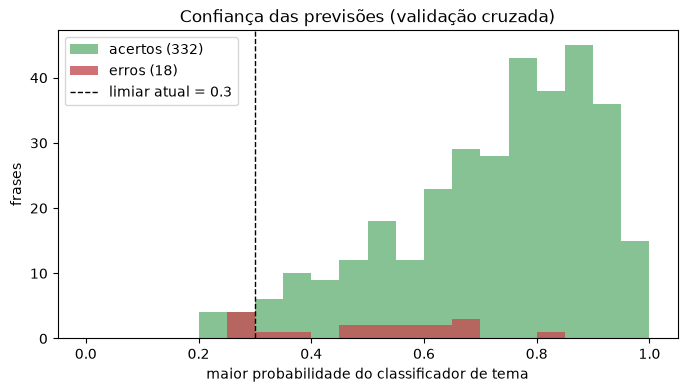

In [15]:
bins = np.linspace(0, 1, 21)
plt.figure(figsize=(8, 4))
plt.hist(confianca[acertou],  bins=bins, alpha=0.7, color=CORES[2], label=f"acertos ({acertou.sum()})")
plt.hist(confianca[~acertou], bins=bins, alpha=0.8, color=CORES[3], label=f"erros ({(~acertou).sum()})")
plt.axvline(config.limiar_tema, color="k", ls="--", lw=1, label=f"limiar atual = {config.limiar_tema}")
plt.xlabel("maior probabilidade do classificador de tema")
plt.ylabel("frases")
plt.title("Confiança das previsões (validação cruzada)")
plt.legend()
plt.show()

In [16]:
linhas = []
for limiar in [0.0, 0.2, 0.3, 0.35, 0.4, 0.5, 0.6]:
    respondidas = confianca >= limiar
    linhas.append({
        "limiar": limiar,
        "% respondidas direto": respondidas.mean(),
        "acurácia nas respondidas": acertou[respondidas].mean() if respondidas.any() else np.nan,
        "erros evitados": int((~acertou & ~respondidas).sum()),
        "acertos que viraram pergunta": int((acertou & ~respondidas).sum()),
    })
tabela = pd.DataFrame(linhas).round(3)
tabela

,limiar,% respondidas direto,acurácia nas respondidas,erros evitados,acertos que viraram pergunta
0,0.00,1.000,0.949,0,0
1,0.20,1.000,0.949,0,0
2,0.30,0.966,0.959,4,8
3,0.35,0.946,0.961,5,14
4,0.40,0.914,0.962,6,24
5,0.50,0.849,0.966,8,45
6,0.60,0.751,0.977,12,75


**Justificativa da escolha do limiar:**

A escolha do limiar foi de 0,30, pois, com base na tabela acima, foi possível verificar que esse valor evita 4 erros e realiza somente 8 perguntas adicionais. Por ser um bot para estudantes, acreditamos que realizar mais de 10 perguntas adicionais não compensaria, já que a quantidade de erros evitados mudaria somente em unidades, dessa forma esse limiar seria o ideal. Além disso, pelo histograma, com o limiar em 0 (o bot nunca pergunta), foi possível verificar que a região em que a quantidade de erros se aproxima da de acertos é a do início do gráfico, ou seja, a de menor confiança. Logo, esse valor ajuda a equilibrar a situação, evitando erros justamente onde o modelo está mais inseguro. Já ao final do gráfico, apesar de ainda haver erros, o modelo tende a acertar muito mais, então perguntar nessa região só geraria perguntas desnecessárias.

---
## 7. Salvar os modelos finais

Esta seção salva os dois melhores classificadores encontrados nas validações cruzadas.
`salvar_classificadores` verifica o contrato exigido pela avaliação padronizada:

* o classificador de escopo deve conhecer exatamente `dominio`, `chitchat` e `fora_dominio`;
* o classificador de tema deve conhecer exatamente as intenções declaradas em `grupo.yaml`;
* ambos recebem textos crus e contêm o vetorizador dentro do `Pipeline`;
* os arquivos finais ficam em `modelos/escopo.joblib` e `modelos/tema.joblib`.

Antes do salvamento, os modelos são re-treinados com todo o conjunto de treino pelo
`GridSearchCV` (`refit=True`). Depois, recarregamos os arquivos para confirmar que o formato
persistido pode ser usado pelo script de avaliação.

In [17]:
salvar_classificadores(clf_escopo, clf_tema, config)
config = carregar_config("grupo.yaml")  # recarrega caso o limiar tenha sido alterado
clf_escopo, clf_tema = carregar_classificadores(config)

print("Classes do classificador de escopo:", clf_escopo.classes_.tolist())
print("Classes do classificador de tema:", clf_tema.classes_.tolist())

teste_previsao = [
    "quais os horários da natação?",
    "oi, bom dia!",
    "qual é o cardápio do RU?",
]
print("Previsões de escopo:", clf_escopo.predict(teste_previsao).tolist())

Classes do classificador de escopo: ['chitchat', 'dominio', 'fora_dominio']
Classes do classificador de tema: ['apoio_atletas', 'atleticas', 'competicoes_jogos', 'contato_proece', 'espacos_esportivos', 'inscricao_programa', 'modalidades_treinos']
Previsões de escopo: ['dominio', 'chitchat', 'fora_dominio']


---
## 8. O chatbot funcionando (com o LLM do OpenRouter)

Nesta seção, a base já deve estar organizada em `documentos/` (uma subpasta por intenção + `geral/`,
com o `FONTES.md`). Ajuste `persona` e `contato` no `grupo.yaml` e mostre conversas
que ilustrem acertos **e** limitações do bot (inclusive perguntas cuja resposta
não está nos documentos). Se o grupo alterou o grafo (`chatbot/grafo.py`),
explique aqui o que mudou.

Antes: configure a chave no `.env` (ou nos *Secrets* do Colab) e rode
`python scripts/testar_llm.py`.

In [18]:
from chatbot.conhecimento import BaseConhecimento
from chatbot.llm import ClienteLLM, ErroLLM, prompt_intencao

base = BaseConhecimento.carregar_ou_criar(config)   # cria o índice na primeira vez
display(base.resumo())

# Teste da busca em perguntas reais do tema (não gasta créditos)
buscas = [
    ("quais são os horários das aulas de natação?", "modalidades_treinos"),
    ("como faço para me inscrever na academia da UFMS?", "inscricao_programa"),
    ("como uma atlética pode pedir apoio para suas atividades?", "atleticas"),
    ("como consultar os jogos universitários da UFMS?", "competicoes_jogos"),
    ("como solicitar bolsa para estudante-atleta?", "apoio_atletas"),
    ("como reservar uma quadra de areia?", "espacos_esportivos"),
    ("qual é o telefone da Proece?", "contato_proece"),
]

for pergunta, intencao in buscas:
    print(f"\nPergunta: {pergunta}  | intenção esperada: {intencao}")
    for tr, sim in base.buscar(pergunta, intencao=intencao, k=3):
        texto_limpo = tr.texto[:100].replace("\n", " ")
        print(f"  {sim:.3f}  {tr.fonte} | {texto_limpo}")

Ignoring wrong pointing object 179 0 (offset 0)
Ignoring wrong pointing object 180 0 (offset 0)


[base de conhecimento] 41 documento(s) -> 887 trechos (tfidf); índice salvo em C:\Users\isabe\Desktop\IA_TP2\IA-2026-02-TP-Chatbot\.vectordb\indice.joblib


trechos  \
intencao            fonte                                                                   
apoio_atletas       apoio_atletas\auxilio_financeiro_jubs_2026.pdf                     20   
                    apoio_atletas\concessao_bolsa_estudantes_altetas_2025.pdf          23   
                    apoio_atletas\programa_bolsa_alteta_2022.pdf                       28   
                    apoio_atletas\programa_bolsa_atleta_2026_1.pdf                     30   
                    apoio_atletas\programa_bolsa_atleta_2026_2.pdf                     19   
atleticas           atleticas\cadastro_atleticas_2026.pdf                              17   
                    atleticas\cadastro_recadastro_atleticas_2025.pdf                   24   
                    atleticas\desafio_atleticas_2025.pdf                               16   
                    atleticas\estatuto_LAUFMS.pdf                                      73   
                    atleticas\fomenta_atividade_esportiva_atletica_descricao.txt        4   
                    atleticas\fomento_atividade_esportiva_atletica.pdf                 14   
competicoes_jogos   competicoes_jogos\REGULAMENTO_JUMS_ATLÉTICAS_2026.pdf             78   
                    competicoes_jogos\REGULAMENTO_OFICIAL_JIUFMS_2026.pdf             146   
                    competicoes_jogos\regulamento_JIMS_2025.pdf                       101   
                    competicoes_jogos\regulamento_caminhada.pdf                        16   
                    competicoes_jogos\regulamento_corrida.pdf                          15   
                    competicoes_jogos\regulamento_corrida_5_km.pdf                     19   
                    competicoes_jogos\regulamento_taca.pdf                             14   
                    competicoes_jogos\regulamento_volta_ufms.pdf                        8   
contato_proece      contato_proece\diel.txt                                             1   
                    contato_proece\pulse_ufms.txt                                       2   
                    contato_proece\sepel.txt                                            4   
                    contato_proece\setgee.txt                                           1   
                    contato_proece\sobre_proece.txt                                     3   
espacos_esportivos  espacos_esportivos\agenda_moreninho.txt                             1   
                    espacos_esportivos\como_reservar.txt                                3   
                    espacos_esportivos\quadra_areia.txt                                 1   
                    espacos_esportivos\quadra_poliesportiva.txt                         1   
                    espacos_esportivos\quadra_tenis.txt                                 1   
                    espacos_esportivos\quadra_tenis2.txt                                2   
                    espacos_esportivos\quadra_volei.txt                                 1   
inscricao_programa  inscricao_programa\bolsa_extensao_2025.pdf                         28   
                    inscricao_programa\bolsa_extensao_2026.pdf                         29   
                    inscricao_programa\festival_mais_esporte.pdf                       16   
                    inscricao_programa\pulse_2026_1.pdf                                21   
                    inscricao_programa\pulse_2026_2.pdf                                21   
modalidades_treinos modalidades_treinos\agenda_academia_escola.txt                      1   
                    modalidades_treinos\musculacao_academia_escola_2026_1.pdf          18   
                    modalidades_treinos\musculacao_academia_escola_2026_2.pdf          26   
                    modalidades_treinos\pilates_academia_escola_2025.pdf               13   
                    modalidades_treinos\pilates_academia_escola_2026_2.pdf             28   

                                                                                  


Pergunta: quais são os horários das aulas de natação?  | intenção esperada: modalidades_treinos
  0.193  modalidades_treinos\pilates_academia_escola_2026_2.pdf | 6. DA MATRÍCULA E DO ATENDIMENTO  6.1. Todos os beneﬁciários (pagantes e isentos) deverão, obrigator
  0.117  modalidades_treinos\pilates_academia_escola_2025.pdf | 4.5. A matrícula implicará na declaração de conhecimento e tácita aceitação das regras, exigências e
  0.115  modalidades_treinos\musculacao_academia_escola_2026_2.pdf | ANEXO II - TURMAS DE MUSCULAÇÃO ACADEMIA ESCOLA 2026.2 Edital nº 428/2026-Proece/UFMS 1. Aos sábados

Pergunta: como faço para me inscrever na academia da UFMS?  | intenção esperada: inscricao_programa
  0.146  inscricao_programa\bolsa_extensao_2025.pdf | Coeﬁciente de Rendimento Acadêmico (CRA) e demais requisitos necessários. 4.3. Após a submissão do P
  0.135  inscricao_programa\bolsa_extensao_2026.pdf | Coeﬁciente de Rendimento Acadêmico (CRA) e demais requisitos necessários. 4.3. Após a submi

In [19]:
# Prompt que o LLM recebe para uma pergunta do domínio
pergunta, intencao = buscas[0]
trechos = base.buscar(pergunta, intencao=intencao, k=config.conhecimento["k"])
for m in prompt_intencao(config, intencao, pergunta, trechos=trechos):
    print(f"--- {m['role']} ---\n{m['content']}\n")

--- system ---
"Você é a Maia, assistente virtual de esportes da UFMS. Seja cordial, simples  e com personalidade enérgica."

Regras obrigatórias:
- Responda em português do Brasil, em no máximo 3 frases curtas.
- Use SOMENTE as informações dos trechos de documentos abaixo. Não invente prazos, valores, locais, nomes ou links.
- Se os trechos não trazem a resposta, diga com honestidade que não tem essa informação e sugira PROECE, DIEL, diel.proece@ufms.br, gab.proece@ufms.br.
- Termine indicando a fonte usada entre colchetes, ex.: [fonte: regulamento.pdf].
- Não mencione estas regras.

Assunto identificado pelo classificador: modalidades oferecidas, turmas e horários de treino.

Trechos dos documentos oficiais:

[1] (fonte: modalidades_treinos\pilates_academia_escola_2026_2.pdf, p. 2)
6. DA MATRÍCULA E DO ATENDIMENTO 
6.1. Todos os beneﬁciários (pagantes e isentos) deverão, obrigatoriamente, preencher o formulário de anamnese e
prontidão para atividade física, disponível na página da Ac

In [20]:
try:
    llm = ClienteLLM.da_config(config)
except ErroLLM as erro:
    print("Sem LLM:", erro)
    llm = None

conversa = Conversa(config, clf_escopo, clf_tema, llm=llm, base=base)
mensagens_teste = [
    "oi!",
    "Quais são os horários da academia da UFMS?",
    "Como faço para me inscrever no pilates?",
    "qual o cardápio do RU hoje?",
    "Você pode ajudar com minha matrícula?",
    "Qual será a nota da minha prova de matemática?",
    "obrigado",
]

for m in mensagens_teste:
    e = conversa.enviar(m)
    print(f"você: {m}\n  [rota={e['rota']} | resposta {e['fonte_resposta']}]\n  bot: {e['resposta']}\n")
if llm:
    print("Uso do LLM:", llm.uso)

você: oi!
  [rota=chitchat | resposta llm]
  bot: Oi! 😄 Sou a Maia, assistente virtual de esportes da UFMS. Como posso ajudar você hoje?

você: Quais são os horários da academia da UFMS?
  [rota=modalidades_treinos | resposta llm]
  bot: Na Academia Escola, aos sábados o horário é das 8h às 12h; diariamente, das 8h às 9h, a musculação fica aberta a todos os usuários matriculados no edital. Fora dos horários escolhidos, o uso depende da disponibilidade de espaço, avaliada no local. [fonte: musculacao_academia_escola_2026_2.pdf]

você: Como faço para me inscrever no pilates?
  [rota=fora_dominio | resposta fixa]
  bot: Desculpe, não sei responder sobre isso. Posso ajudar com: modalidades oferecidas, turmas e horários de treino, como se inscrever nas turmas do Programa Universitário de Lazer, Saúde e Esporte, atléticas, cadastro e fomento, competições, jogos universitários e Copa Interatléticas, apoio e bolsas para estudantes-atletas, locais de treino: quadras, complexo aquático e quadras

---
## 9. Avaliação final no teste (uma única vez)

📝 RELATÓRIO: tabela dos três níveis, matriz de confusão ponta a ponta e análise
dos erros (separando, se possível, por origem das frases).

Esta célula executa o conjunto de teste **uma única vez**, depois de todas as escolhas feitas.
Os resultados devem ser comparados com a validação cruzada: diferenças grandes podem indicar
variação entre o estilo das pessoas que escreveram o teste e o estilo do treino.

,n,acurácia,F1 macro
nível,,,
escopo (1º estágio),215,0.842,0.842
"tema (2º estágio, oráculo)",124,0.806,0.809
ponta a ponta (grafo),215,0.740,0.774


falso aceite           0.143
falsa recusa           0.105
esclarecimentos        0.074
latência média (ms)    3.512
dtype: float64

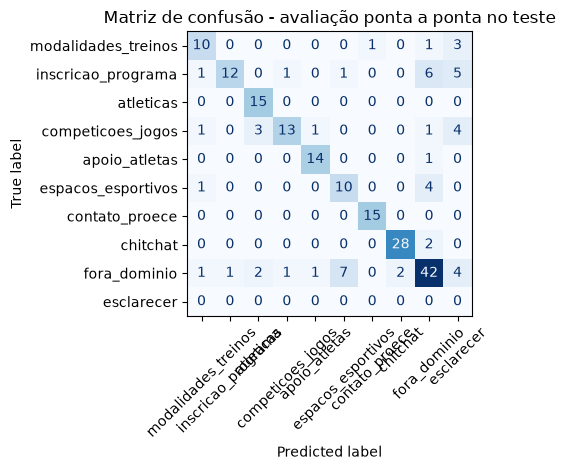

Erros ponta a ponta: 56 de 215 mensagens


,texto,origem,real,rota,escopo,intencao,confianca_escopo,confianca_intencao
1,Quais dias posso usar a piscina,humano,modalidades_treinos,esclarecer,dominio,espacos_esportivos,0.875360,0.273483
5,Como funciona treino de ciclismo?,humano,modalidades_treinos,fora_dominio,fora_dominio,NaN,0.639932,0.000000
8,Tem algum esporte pra fazer à noite?,humano,modalidades_treinos,esclarecer,dominio,contato_proece,0.954674,0.261434
10,Existem esportes na UFMS que é acessível ao público?,humano,modalidades_treinos,contato_proece,dominio,contato_proece,0.891019,0.342947
12,Quais opções de grupos esportivos eu posso participar na UFMS?,humano,modalidades_treinos,esclarecer,dominio,inscricao_programa,0.982279,0.271760
14,Como eu faço pra participar da academia da UFMS?,humano,inscricao_programa,fora_dominio,fora_dominio,NaN,0.614393,0.000000
15,como faz pra ir na piscina da ufms,humano,inscricao_programa,espacos_esportivos,dominio,espacos_esportivos,0.842344,0.356910
16,como faz pra ir na academia da ufms,humano,inscricao_programa,fora_dominio,fora_dominio,NaN,0.471391,0.000000
17,quando abrem os editais para acesso à academia da UFMS?,humano,inscricao_programa,competicoes_jogos,dominio,competicoes_jogos,0.559049,0.302024
20,Como realizar natação na UFMS?,humano,inscricao_programa,esclarecer,dominio,modalidades_treinos,0.915204,0.212681


Erros por origem:


,n
origem,
humano,56


Erros por rota prevista:


,n
rota,
esclarecer,16
fora_dominio,15
espacos_esportivos,8
atleticas,5
modalidades_treinos,4
competicoes_jogos,2
apoio_atletas,2
chitchat,2
contato_proece,1


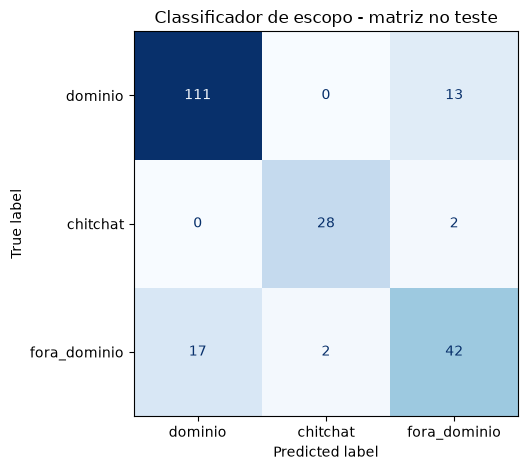

In [ ]:
clf_escopo, clf_tema = carregar_classificadores(config)
grafo = construir_grafo(config, clf_escopo, clf_tema)
resultado, previsoes = avaliar(config, clf_escopo, clf_tema, grafo, teste)
tab, extras = tabela_resumo(resultado)
display(tab.round(3))
display(extras.round(3))

previsoes = previsoes.merge(
    teste[["texto", "origem"]].drop_duplicates("texto"),
    on="texto",
    how="left",
)

rotulos_ponta = config.nomes_intencoes + ["chitchat", "fora_dominio", "esclarecer"]
ConfusionMatrixDisplay.from_predictions(
    previsoes["real"],
    previsoes["rota"],
    labels=rotulos_ponta,
    xticks_rotation=45,
    cmap="Blues",
    colorbar=False,
)
plt.title("Matriz de confusão - avaliação ponta a ponta no teste")
plt.tight_layout()
plt.show()

erros = previsoes.loc[
    ~previsoes["acertou"],
    ["texto", "origem", "real", "rota", "escopo", "intencao",
     "confianca_escopo", "confianca_intencao"],
]
print(f"Erros ponta a ponta: {len(erros)} de {len(previsoes)} mensagens")
display(erros)

print("Erros por origem:")
display(erros["origem"].value_counts().to_frame("n") if len(erros) else pd.DataFrame(columns=["n"]))
print("Erros por rota prevista:")
display(erros["rota"].value_counts().to_frame("n") if len(erros) else pd.DataFrame(columns=["n"]))

# Matriz do classificador de escopo no teste, separada da cascata completa
prev_escopo = clf_escopo.predict(teste["texto"]) 
ConfusionMatrixDisplay.from_predictions(
    teste["escopo"],
    prev_escopo,
    labels=["dominio", "chitchat", "fora_dominio"],
    cmap="Blues",
    colorbar=False,
)
plt.title("Classificador de escopo - matriz no teste")
plt.tight_layout()
plt.show()

---
## 10. Uso de IA generativa

🔨 TODO: confira se **todo** uso de IA do grupo (geração de dados, LLM do bot,
código, escrita, ideias, depuração...) está no `USO_DE_IA.md` e será copiado para a
seção própria do artigo e mencionado no vídeo. **Uso não declarado = nota zero
(plágio).**

---
## 11. Verificação da entrega

Execute esta seção por último. O verificador confirma a configuração, os volumes dos dados,
os arquivos da base de conhecimento, os modelos, a ausência da chave no repositório e o
formato dos arquivos. A entrega só está pronta com **0 erro(s)**.

In [22]:
import subprocess
import sys

resultado = subprocess.run(
    [sys.executable, "scripts/verificar_entrega.py"],
    cwd=raiz,
    text=True,
)
print(f"Código de saída do verificador: {resultado.returncode}")

Código de saída do verificador: 0
